# Backbone transfer: CNN-LSTM, TCN, Transformer on Panasonic to CMU eVTOL

This notebook runs `scripts/benchmarks/run_backbone_transfer_cmu.py`, which
reimplements the Vidal transfer protocol (Panasonic 25 C 1 Hz source, nested
chronological target-label budgets 0/1/5/10/40/100%, full-parameter fine-tuning
restarted from the frozen source checkpoint at every budget) for three generic
backbones already registered in `battery_benchmark.models`: `cnn_lstm`, `tcn`,
and `transformer_encoder`. It does not import or modify
`battery_benchmark.reproductions.vidal_2019`; the published Vidal LSTM CMU
results in `docs/benchmarks/vidal_panasonic_to_cmu_evtol_results_v0_1.md` are
unaffected.

Checkpointing is fine-grained: the source checkpoint for each (model, seed) is
saved to Drive as soon as it finishes, and every single (model, seed, cell,
budget) result is written to its own file the moment it finishes -- `cell_metrics.csv`
is rewritten after every one of those, not just once per cell. `--resume`
skips anything already on disk, so a Colab disconnect costs at most the one
budget that was in flight, not a whole cell or backbone.

CMU `soc_dynamic` is a development reference, not laboratory ground truth;
these runs are `formal_benchmark_eligible=false`.

In [5]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('Repository ready:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())

Mounted at /content/drive
Repository ready: a29093ed66040bb1fbfee47e496824f08d814a63


## Paths (Drive-persisted input/output roots)

Defined once, right after the clone, so every later cell -- including the
smoke test -- uses the real Drive-mounted Panasonic path instead of a
fallback that only exists for people who haven't set up
`configs/paths/colab_drive.yaml`.

In [6]:
import torch
from battery_benchmark.utils.config import load_yaml

PATHS = load_yaml(REPO / 'configs/paths/colab_drive.yaml')
PANASONIC_ROOT = Path(PATHS['raw_data_root']) / 'Panasonic_18650PF'
CMU_BASE_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel'
CMU_CONDITION_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel'
CMU_MANIFEST = REPO / 'data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv'
RESULT_ROOT = Path(PATHS['output_root']) / 'benchmarks/panasonic_to_cmu_evtol/backbone_transfer_ns_relabel_v2'

for path in (PANASONIC_ROOT, CMU_BASE_ROOT, CMU_CONDITION_ROOT, CMU_MANIFEST):
    assert path.exists(), f'Missing required input: {path}'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
print('panasonic root:', PANASONIC_ROOT)
print('results (saved to Drive, survives a disconnect):', RESULT_ROOT)

device: cuda
panasonic root: /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF
results (saved to Drive, survives a disconnect): /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/backbone_transfer_ns_relabel_v2


## Protocol

- Source: Panasonic NCR18650PF, 25 C only, all nine profiles, 1 Hz, 50-step
  non-overlapping windows, train-only min-max normalisation (matches the
  Vidal Case 1 reconstruction assumptions documented in
  `docs/known_uncertainties.md`).
- Target budgets: `zero_shot`, `1pct`, `5pct`, `10pct`, `partial` (~40%), `full`
  (100%) -- the same nested mission-budget flags already frozen in
  `cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv` and used by the published
  Vidal LSTM sweep, so budget points line up exactly across backbones.
- Every budget restarts full-parameter fine-tuning from the same frozen
  source checkpoint (Vidal Case 2 pattern); no adapted state carries across
  budgets or cells.
- Model capacity is intentionally left at each backbone's default
  configuration rather than shrunk to match Vidal's 571-parameter LSTM;
  `n_parameters` is recorded per model in every result row and in
  `run_metadata.json` so capacity differences stay visible rather than being
  read as an architecture effect.

## Before the full sweep: a 2-minute smoke test

Run this once after a fresh clone/pull to catch a broken import or a bad
path before committing GPU time to the full sweep. It uses 2 epochs, one
cell, and two budgets, and writes to a throwaway output folder.

In [7]:
smoke_root = Path('/content/backbone_smoke_test')
subprocess.run(
    [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_backbone_transfer_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(smoke_root),
        '--models', 'cnn_lstm',
        '--cells', 'VAH01',
        '--budgets', 'zero_shot', '1pct',
        '--source-epochs', '2', '--transfer-epochs', '2',
        '--device', device,
    ],
    check=True,
)
print('smoke test passed')

smoke test passed


## Setup for the full sweep

`SEEDS = [42]` by default -- extend to `[42, 43, 44]` for a 3-seed run once
the single-seed sweep looks sane. Multi-seed multiplies the source
pretraining cost by the number of seeds, so it's worth checking the
single-seed curve first.

In [8]:
import pandas as pd
from IPython.display import display

CELLS = ['VAH01', 'VAH17', 'VAH27', 'VAH30', 'VAH15', 'VAH12', 'VAH11']
BUDGETS = ['zero_shot', '1pct', '5pct', '10pct', 'partial', 'full']
SEEDS = [42]
SOURCE_EPOCHS, TRANSFER_EPOCHS, BATCH_SIZE = 200, 100, 64

def run_backbone(model_name: str) -> None:
    command = [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_backbone_transfer_cmu.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--output-root', str(RESULT_ROOT),
        '--models', model_name,
        '--cells', *CELLS,
        '--budgets', *BUDGETS,
        '--seeds', *[str(s) for s in SEEDS],
        '--source-epochs', str(SOURCE_EPOCHS),
        '--transfer-epochs', str(TRANSFER_EPOCHS),
        '--batch-size', str(BATCH_SIZE),
        '--device', device,
        '--resume',
    ]
    subprocess.run(command, check=True)

## Run: cnn_lstm

Split into one cell per backbone so a disconnect during (say) `tcn` doesn't
require re-touching `cnn_lstm`'s already-finished cells -- with `--resume`
and the fine-grained checkpointing above, re-running a finished backbone's
cell is nearly instant (every budget is skipped).

In [7]:
run_backbone('cnn_lstm')

## Run: tcn

In [9]:
run_backbone('tcn')

## Run: transformer_encoder

In [10]:
run_backbone('transformer_encoder')

## Results -- read straight from Drive, one model at a time

Each model below reads only its own subfolder under `RESULT_ROOT`
(`RESULT_ROOT / '<model_name>'`) directly off Drive and plots on its own --
no shared aggregation step, and no dependency on `cell_metrics.csv` (an
older version of the run script overwrote that file per-model instead of
merging, so it may only reflect whichever backbone happened to run last).
Nothing here requires re-cloning or re-running the training script; it just
re-reads whatever per-(seed, cell, budget) JSON files are already sitting in
Drive right now (`<cell>/<budget>.json`, one flat result row per file -- this
is what the run script actually writes for fine-grained resume; a couple of
early cells also still have an old-format `<cell>/result.json` with a
`metrics` list inside from before that -- `load_model_results` below reads
either shape so nothing has to be manually cleaned up on Drive).

`budget_order` and `load_model_results` are shared helpers (no I/O, no
plotting) -- everything that actually touches Drive or draws a chart is
its own cell below.

In [11]:
import json as _json

budget_order = ['zero_shot', '1pct', '5pct', '10pct', 'partial', 'full']

def load_model_results(result_root: Path, model_name: str) -> pd.DataFrame:
    '''Read every seed/cell/budget result JSON for one model directly out of Drive.

    Handles both file shapes: the current one row per <budget>.json, and the
    old one metrics-list per <cell>/result.json.
    '''
    rows = []
    for result_path in sorted((result_root / model_name).glob('seed_*/*/*.json')):
        payload = _json.loads(result_path.read_text(encoding='utf-8'))
        if 'metrics' in payload:  # old shape: one file per cell, list of budget rows
            rows.extend(payload['metrics'])
        else:  # current shape: one file per (cell, budget), already a flat row
            rows.append(payload)
    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.drop_duplicates(subset=['model', 'cell_id', 'budget', 'seed'], keep='last')
    return df

### cnn_lstm

Vidal LSTM reference (same six budget points, unweighted mean cell MAE):
35.56 / 8.29 / 6.72 / 5.77 / 5.67 / 2.49 for zero-shot / 1% / 5% / 10% /
Partial / Full.

cnn_lstm rows: 42


overall_mae_percent                                           \
budget                10pct    1pct    5pct   full partial zero_shot   
cell_id                                                                
VAH01                 7.738   5.399   5.624  1.848   4.278     9.298   
VAH11                10.814  13.557  10.834  4.958   8.328     5.528   
VAH12                 9.934  11.056  10.543  2.030   3.897     8.917   
VAH15                 2.505   3.672   3.049  0.897   2.358     9.033   
VAH17                 5.537   4.908   5.431  1.753   3.768    10.003   
VAH27                 5.243   5.753   5.801  2.476   4.370     7.725   
VAH30                 7.594   9.613   9.305  2.175   3.728    19.956   

        overall_rmse_percent                                           
budget                 10pct    1pct    5pct   full partial zero_shot  
cell_id                                                                
VAH01                  9.940   8.801   8.781  2.812   7.215    10.475  
VAH11                 13.552  16.320  14.511  6.124   9.902     9.664  
VAH12                 14.094  15.446  14.507  3.149   6.578    10.389  
VAH15                  4.398   5.490   5.002  1.433   3.458     9.625  
VAH17                  8.199   7.985   8.323  3.488   5.522    11.114  
VAH27                  7.606   7.890   7.757  3.807   5.767     8.490  
VAH30                  9.842  11.820  11.504  4.493   6.966    21.718

,overall_mae_percent
budget,
zero_shot,10.066
1pct,7.708
5pct,7.227
10pct,7.052
partial,4.390
full,2.305


<Axes: title={'center': 'cnn_lstm'}, xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

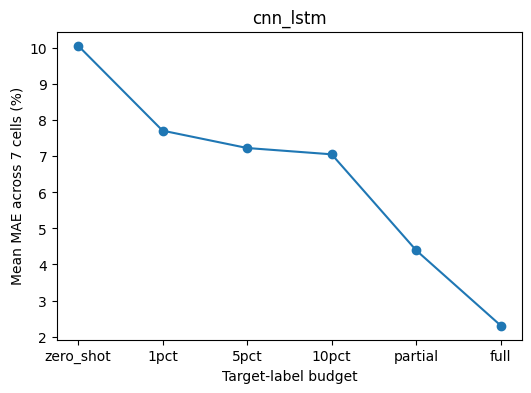

In [12]:
cnn_lstm_result = load_model_results(RESULT_ROOT, 'cnn_lstm')
print('cnn_lstm rows:', len(cnn_lstm_result))

cnn_lstm_pivot = cnn_lstm_result.pivot_table(
    index='cell_id', columns='budget',
    values=['overall_mae_percent', 'overall_rmse_percent'],
).round(3)
display(cnn_lstm_pivot)

cnn_lstm_curve = (
    cnn_lstm_result.groupby('budget')['overall_mae_percent']
    .mean().reindex(budget_order).round(3)
)
display(cnn_lstm_curve)
cnn_lstm_curve.plot(
    marker='o', figsize=(6, 4), title='cnn_lstm',
    ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget',
)

### tcn

tcn rows: 42


overall_mae_percent                                           \
budget                10pct    1pct    5pct   full partial zero_shot   
cell_id                                                                
VAH01                 4.160   4.802   4.966  2.956   4.640     6.756   
VAH11                11.543  12.372  11.617  5.214   8.190    10.401   
VAH12                10.230  13.205  11.767  3.250   3.579    11.631   
VAH15                 3.573   5.167   3.973  1.074   2.290     6.956   
VAH17                 4.439   7.514   5.986  2.000   4.601     7.348   
VAH27                 6.254   6.806   7.015  2.023   5.344     7.309   
VAH30                10.102  14.586  11.905  2.117   3.878     5.524   

        overall_rmse_percent                                           
budget                 10pct    1pct    5pct   full partial zero_shot  
cell_id                                                                
VAH01                  7.964   8.375   8.235  4.742   7.487     9.097  
VAH11                 14.418  15.550  14.864  6.966  10.302    17.688  
VAH12                 14.002  16.266  15.110  4.993   7.353    17.341  
VAH15                  5.290   6.741   5.488  1.388   3.888     8.151  
VAH17                  7.697   9.613   8.455  3.837   6.815     9.538  
VAH27                  7.791   8.594   8.437  3.114   6.862     9.884  
VAH30                 12.207  16.037  13.633  5.125   7.303     7.989

,overall_mae_percent
budget,
zero_shot,7.989
1pct,9.207
5pct,8.176
10pct,7.186
partial,4.646
full,2.662


<Axes: title={'center': 'tcn'}, xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

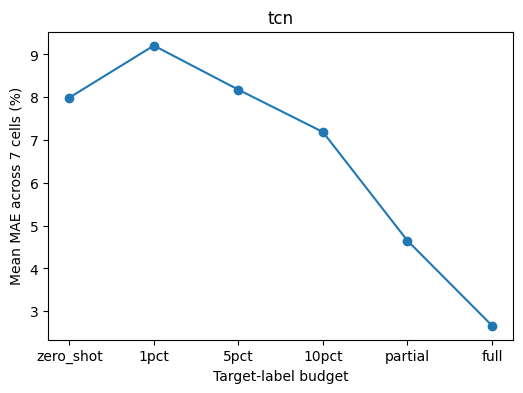

In [13]:
tcn_result = load_model_results(RESULT_ROOT, 'tcn')
print('tcn rows:', len(tcn_result))

tcn_pivot = tcn_result.pivot_table(
    index='cell_id', columns='budget',
    values=['overall_mae_percent', 'overall_rmse_percent'],
).round(3)
display(tcn_pivot)

tcn_curve = (
    tcn_result.groupby('budget')['overall_mae_percent']
    .mean().reindex(budget_order).round(3)
)
display(tcn_curve)
tcn_curve.plot(
    marker='o', figsize=(6, 4), title='tcn',
    ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget',
)

### transformer_encoder

transformer_encoder rows: 42


overall_mae_percent                                           \
budget                10pct    1pct    5pct   full partial zero_shot   
cell_id                                                                
VAH01                 9.100  15.781  11.660  2.369   3.231    10.323   
VAH11                 7.701  11.316   7.411  4.106   7.163     6.441   
VAH12                 6.534  13.372  11.886  1.103   3.593    11.512   
VAH15                 4.052   5.404   4.418  0.667   1.582    11.926   
VAH17                 8.289  12.101   8.875  1.406   3.544    11.607   
VAH27                 5.772   8.041   6.451  1.915   3.328    11.154   
VAH30                11.385  12.402  11.736  2.396   3.528    11.714   

        overall_rmse_percent                                           
budget                 10pct    1pct    5pct   full partial zero_shot  
cell_id                                                                
VAH01                 10.651  17.214  13.251  3.087   5.782    12.191  
VAH11                 10.978  14.038  10.976  4.901   9.736    12.216  
VAH12                 10.083  15.530  13.725  1.496   6.220    15.199  
VAH15                  5.424   7.089   6.171  1.150   3.389    13.567  
VAH17                 10.775  13.793  11.150  2.579   5.738    13.384  
VAH27                  7.596   9.973   8.181  2.723   5.313    13.171  
VAH30                 14.878  15.288  15.104  3.488   6.868    14.218

,overall_mae_percent
budget,
zero_shot,10.668
1pct,11.202
5pct,8.920
10pct,7.548
partial,3.710
full,1.995


<Axes: title={'center': 'transformer_encoder'}, xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

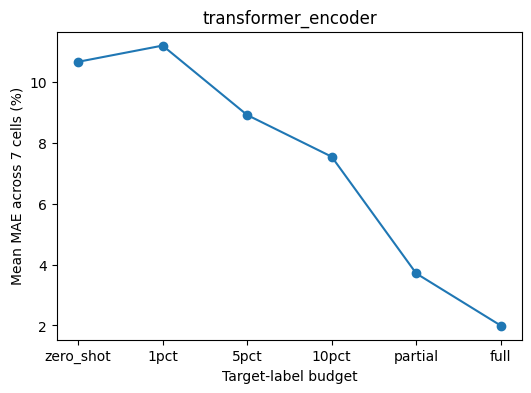

In [14]:
transformer_result = load_model_results(RESULT_ROOT, 'transformer_encoder')
print('transformer_encoder rows:', len(transformer_result))

transformer_pivot = transformer_result.pivot_table(
    index='cell_id', columns='budget',
    values=['overall_mae_percent', 'overall_rmse_percent'],
).round(3)
display(transformer_pivot)

transformer_curve = (
    transformer_result.groupby('budget')['overall_mae_percent']
    .mean().reindex(budget_order).round(3)
)
display(transformer_curve)
transformer_curve.plot(
    marker='o', figsize=(6, 4), title='transformer_encoder',
    ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget',
)

### All three together (only run once each of the above has data)

Combines the three per-model tables already loaded above -- still no fresh
Drive scan, just lining up the three curves for a side-by-side comparison.

model,cnn_lstm,tcn,transformer_encoder
budget,,,
zero_shot,10.066,7.989,10.668
1pct,7.708,9.207,11.202
5pct,7.227,8.176,8.920
10pct,7.052,7.186,7.548
partial,4.390,4.646,3.710
full,2.305,2.662,1.995


<Axes: xlabel='Target-label budget', ylabel='Mean MAE across 7 cells (%)'>

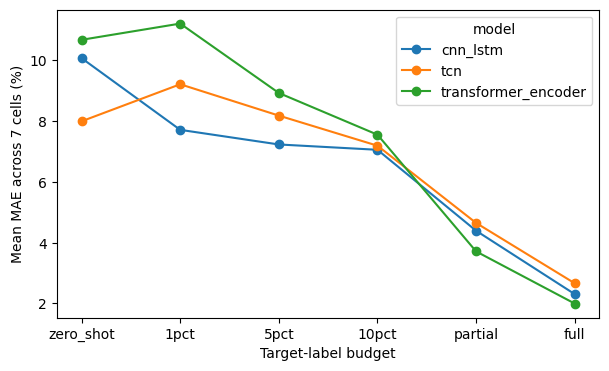

In [15]:
combined = pd.concat([cnn_lstm_result, tcn_result, transformer_result], ignore_index=True)

combined_curve = (
    combined.groupby(['model', 'budget'])['overall_mae_percent']
    .mean()
    .unstack('model')
    .reindex(budget_order)
    .round(3)
)
display(combined_curve)
combined_curve.plot(marker='o', figsize=(7, 4), ylabel='Mean MAE across 7 cells (%)', xlabel='Target-label budget')

## Diagnostics: cell/budget negative transfer, phase-level effects, training curves

Everything below is read straight back from what the script already wrote
under `RESULT_ROOT` -- `cell_metrics.csv` (already loaded above as
`cnn_lstm_result`/`tcn_result`/`transformer_result`/`combined`),
`cell_transfer_effects.csv`, `phase_metrics.csv`, `phase_transfer_effects.csv`,
and `training_history.csv` -- nothing here re-runs the model or recomputes a
metric from scratch. Covers all three backbones together.

### Cell/budget negative transfer

The mean-MAE curve per budget (plotted above, one number per budget,
averaged across all 7 cells) hides how much any individual cell got WORSE
under fine-tuning -- a budget can look good on average while still making
some cells worse than zero-shot. `cell_transfer_effects.csv` is the
OVERALL-level (never phase-restricted) delta for every (model, cell,
budget) vs. zero_shot; shown here per cell, never just a model-wide
average.

In [16]:
cell_transfer_effects_path = RESULT_ROOT / 'cell_transfer_effects.csv'

if cell_transfer_effects_path.is_file():
    cell_transfer_effects = pd.read_csv(cell_transfer_effects_path)
    display(cell_transfer_effects.round(3))

    summary_rows = []
    for model_name, model_rows in cell_transfer_effects.groupby('model'):
        for budget, budget_rows in model_rows.groupby('budget'):
            n_cells = len(budget_rows)
            n_negative_mae = int(budget_rows['negative_transfer_mae'].sum())
            n_negative_rmse = int(budget_rows['negative_transfer_rmse'].sum())
            summary_rows.append(
                {
                    'model': model_name, 'budget': budget, 'n_cells': n_cells,
                    'negative_transfer_mae_count': n_negative_mae,
                    'negative_transfer_mae_pct': round(100 * n_negative_mae / n_cells, 1),
                    'negative_transfer_rmse_count': n_negative_rmse,
                    'negative_transfer_rmse_pct': round(100 * n_negative_rmse / n_cells, 1),
                }
            )
    display(pd.DataFrame(summary_rows))
else:
    cell_transfer_effects = pd.DataFrame()
    print('No cell_transfer_effects.csv yet under', RESULT_ROOT)

,model,cell_id,condition,budget,reference_budget,seed,zero_shot_mae_percent,adapted_mae_percent,delta_mae_percent,zero_shot_rmse_percent,adapted_rmse_percent,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,cnn_lstm,VAH01,baseline protocol,10pct,zero_shot,42,9.298,7.738,-1.560,10.475,9.940,-0.535,False,False
1,cnn_lstm,VAH11,20% lower discharge power,10pct,zero_shot,42,5.528,10.814,5.286,9.664,13.552,3.888,True,True
2,cnn_lstm,VAH12,short 400 s cruise,10pct,zero_shot,42,8.917,9.934,1.017,10.389,14.094,3.705,True,True
3,cnn_lstm,VAH15,extended 1000 s cruise,10pct,zero_shot,42,9.033,2.505,-6.528,9.625,4.398,-5.227,False,False
4,cnn_lstm,VAH17,baseline protocol,10pct,zero_shot,42,10.003,5.537,-4.466,11.114,8.199,-2.915,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,transformer_encoder,VAH12,short 400 s cruise,partial,zero_shot,42,11.512,3.593,-7.919,15.199,6.220,-8.979,False,False
101,transformer_encoder,VAH15,extended 1000 s cruise,partial,zero_shot,42,11.926,1.582,-10.344,13.567,3.389,-10.178,False,False
102,transformer_encoder,VAH17,baseline protocol,partial,zero_shot,42,11.607,3.544,-8.063,13.384,5.738,-7.646,False,False
103,transformer_encoder,VAH27,baseline protocol,partial,zero_shot,42,11.154,3.328,-7.826,13.171,5.313,-7.858,False,False


,model,budget,n_cells,negative_transfer_mae_count,negative_transfer_mae_pct,negative_transfer_rmse_count,negative_transfer_rmse_pct
0,cnn_lstm,10pct,7,2,28.6,2,28.6
1,cnn_lstm,1pct,7,2,28.6,2,28.6
2,cnn_lstm,5pct,7,2,28.6,2,28.6
3,cnn_lstm,full,7,0,0.0,0,0.0
4,cnn_lstm,partial,7,1,14.3,1,14.3
5,tcn,10pct,7,2,28.6,1,14.3
6,tcn,1pct,7,4,57.1,2,28.6
7,tcn,5pct,7,3,42.9,1,14.3
8,tcn,full,7,0,0.0,0,0.0
9,tcn,partial,7,0,0.0,0,0.0


### Phase-level metrics and transfer effects (take_off / cruise / landing)

`phase_metrics.csv` and `phase_transfer_effects.csv` are written once per
invocation by the script, read back here directly (restricted to the
three flight phases; every value is exactly recomputable from
`test_predictions.parquet`'s own columns). Every non-zero_shot budget is
compared against `zero_shot` separately via the `reference_budget`
column -- `delta = adapted - zero_shot`, so `delta > 0` means negative
transfer for that (model, cell, budget, phase).

In [17]:
phase_metrics_path = RESULT_ROOT / 'phase_metrics.csv'
phase_transfer_effects_path = RESULT_ROOT / 'phase_transfer_effects.csv'

if phase_metrics_path.is_file():
    phase_metrics = pd.read_csv(phase_metrics_path)
    display(phase_metrics.round(3))
else:
    phase_metrics = pd.DataFrame()
    print('No phase_metrics.csv yet under', RESULT_ROOT)

if phase_transfer_effects_path.is_file():
    phase_transfer_effects = pd.read_csv(phase_transfer_effects_path)
    display(phase_transfer_effects.round(3))

    negative_transfer_summary = (
        phase_transfer_effects
        .groupby(['model', 'budget', 'mission_phase'])[['negative_transfer_mae', 'negative_transfer_rmse']]
        .mean()
        .round(3)
    )
    print('Fraction of cells showing negative transfer, by model/budget/phase:')
    display(negative_transfer_summary)
else:
    phase_transfer_effects = pd.DataFrame()
    print('No phase_transfer_effects.csv yet under', RESULT_ROOT)

,model,cell_id,condition,budget,mission_phase,n_points,n_missions,mae_percent,rmse_percent,mean_signed_error_percent
0,cnn_lstm,VAH01,baseline protocol,10pct,take_off,12570,170,22.062,23.884,-22.050
1,cnn_lstm,VAH01,baseline protocol,10pct,cruise,161600,170,6.567,7.911,2.274
2,cnn_lstm,VAH01,baseline protocol,10pct,landing,12480,170,8.474,9.636,-4.228
3,cnn_lstm,VAH01,baseline protocol,1pct,take_off,12570,170,22.124,24.020,-22.109
4,cnn_lstm,VAH01,baseline protocol,1pct,cruise,161600,170,3.888,6.124,-1.579
...,...,...,...,...,...,...,...,...,...,...
373,transformer_encoder,VAH30,35 °C chamber,partial,cruise,173600,185,2.041,2.667,-1.302
374,transformer_encoder,VAH30,35 °C chamber,partial,landing,13655,185,3.514,3.871,3.514
375,transformer_encoder,VAH30,35 °C chamber,zero_shot,take_off,13695,185,3.306,4.106,2.995
376,transformer_encoder,VAH30,35 °C chamber,zero_shot,cruise,173600,185,10.675,11.953,7.050


,model,cell_id,condition,budget,reference_budget,mission_phase,zero_shot_mae_percent,adapted_mae_percent,delta_mae_percent,zero_shot_rmse_percent,adapted_rmse_percent,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,cnn_lstm,VAH01,baseline protocol,10pct,zero_shot,take_off,8.214,22.062,13.848,9.981,23.884,13.903,True,True
1,cnn_lstm,VAH01,baseline protocol,10pct,zero_shot,cruise,9.538,6.567,-2.970,10.599,7.911,-2.688,False,False
2,cnn_lstm,VAH01,baseline protocol,10pct,zero_shot,landing,7.288,8.474,1.186,9.271,9.636,0.365,True,True
3,cnn_lstm,VAH11,20% lower discharge power,10pct,zero_shot,take_off,22.774,30.552,7.778,24.526,31.872,7.346,True,True
4,cnn_lstm,VAH11,20% lower discharge power,10pct,zero_shot,cruise,3.120,8.203,5.083,5.237,9.050,3.813,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,transformer_encoder,VAH27,baseline protocol,partial,zero_shot,cruise,10.590,2.411,-8.179,12.165,2.820,-9.345,False,False
311,transformer_encoder,VAH27,baseline protocol,partial,zero_shot,landing,25.035,2.211,-22.824,25.573,2.553,-23.020,False,False
312,transformer_encoder,VAH30,35 °C chamber,partial,zero_shot,take_off,3.306,22.395,19.089,4.106,24.226,20.120,True,True
313,transformer_encoder,VAH30,35 °C chamber,partial,zero_shot,cruise,10.675,2.041,-8.634,11.953,2.667,-9.286,False,False


Fraction of cells showing negative transfer, by model/budget/phase:


negative_transfer_mae  \
model               budget  mission_phase                          
cnn_lstm            10pct   cruise                         0.143   
                            landing                        0.571   
                            take_off                       1.000   
                    1pct    cruise                         0.143   
                            landing                        0.714   
                            take_off                       1.000   
                    5pct    cruise                         0.143   
                            landing                        0.714   
                            take_off                       1.000   
                    full    cruise                         0.143   
                            landing                        0.000   
                            take_off                       0.571   
                    partial cruise                         0.143   
                            landing                        0.143   
                            take_off                       0.714   
tcn                 10pct   cruise                         0.286   
                            landing                        0.429   
                            take_off                       1.000   
                    1pct    cruise                         0.286   
                            landing                        0.857   
                            take_off                       1.000   
                    5pct    cruise                         0.286   
                            landing                        0.714   
                            take_off                       1.000   
                    full    cruise                         0.000   
                            landing                        0.000   
                            take_off                       0.571   
                    partial cruise                         0.000   
                            landing                        0.000   
                            take_off                       0.714   
transformer_encoder 10pct   cruise                         0.143   
                            landing                        0.000   
                            take_off                       1.000   
                    1pct    cruise                         0.714   
                            landing                        0.143   
                            take_off                       1.000   
                    5pct    cruise                         0.429   
                            landing                        0.000   
                            take_off                       1.000   
                    full    cruise                         0.000   
                            landing                        0.000   
                            take_off                       0.571   
                    partial cruise                         0.143   
                            landing                        0.000   
                            take_off                       1.000   

                                           negative_transfer_rmse  
model               budget  mission_phase                          
cnn_lstm            10pct   cruise                          0.143  
                            landing                         0.571  
                            take_off                        1.000  
                    1pct    cruise                          0.143  
                            landing                         0.714  
                            take_off                        1.000  
                    5pct    cruise                          0.143  
                            landing                         0.429  
                            take_off                        1.000  
                    full    cruise                          0.143  
                            la

### Training and validation curves

`training_history.csv` has one row per (model, seed[, cell, budget],
epoch). Source-pretraining rows have no `cell_id`/`budget` (pretraining
happens once per model/seed); fine-tuning rows do. Where the CMU
manifest's diagnostic-only `validation` split had complete windows for a
cell, `validation_mae`/`validation_rmse` are also recorded per epoch --
this is a READ-ONLY probe that never fed back into training, early
stopping, or checkpoint selection (every budget always fine-tunes for the
full configured epoch count from the frozen source checkpoint; see
`run_metadata.json`'s `validation_protocol` note).

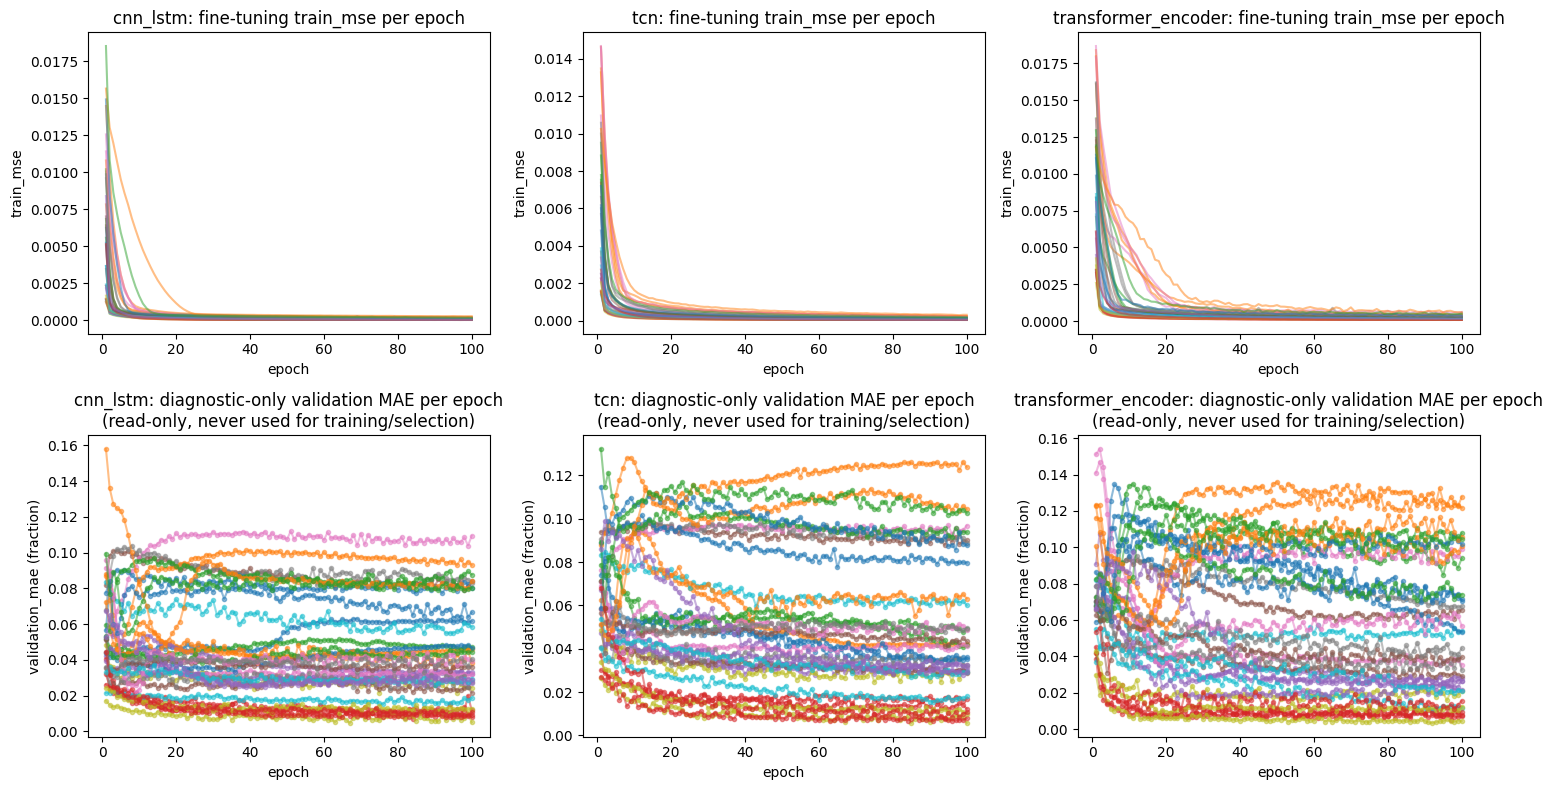

In [18]:
import matplotlib.pyplot as plt

training_history_path = RESULT_ROOT / 'training_history.csv'

if training_history_path.is_file():
    training_history = pd.read_csv(training_history_path)
else:
    training_history = pd.DataFrame()
    print('No training_history.csv yet under', RESULT_ROOT)

if not training_history.empty:
    fine_tune_rows = training_history.loc[training_history['budget'].notna()] if 'budget' in training_history.columns else pd.DataFrame()
    models_present = sorted(fine_tune_rows['model'].unique()) if not fine_tune_rows.empty else []
    if models_present:
        fig, axes = plt.subplots(2, len(models_present), figsize=(5 * len(models_present), 8), squeeze=False)
        for col, model_name in enumerate(models_present):
            rows = fine_tune_rows.loc[fine_tune_rows['model'] == model_name]
            loss_ax, val_ax = axes[0, col], axes[1, col]
            for (cell_id, budget), group in rows.groupby(['cell_id', 'budget']):
                loss_ax.plot(group['epoch'], group['train_mse'], label=f'{cell_id}/{budget}', alpha=0.5)
            loss_ax.set_title(f'{model_name}: fine-tuning train_mse per epoch')
            loss_ax.set_xlabel('epoch')
            loss_ax.set_ylabel('train_mse')

            evaluated = rows.loc[rows['validation_evaluated'] == True]
            if evaluated.empty:
                val_ax.set_title(f'{model_name}: no validation diagnostics recorded')
                val_ax.axis('off')
                continue
            for (cell_id, budget), group in evaluated.groupby(['cell_id', 'budget']):
                val_ax.plot(group['epoch'], group['validation_mae'], marker='.', label=f'{cell_id}/{budget}', alpha=0.5)
            val_ax.set_title(f'{model_name}: diagnostic-only validation MAE per epoch\n(read-only, never used for training/selection)')
            val_ax.set_xlabel('epoch')
            val_ax.set_ylabel('validation_mae (fraction)')
        plt.tight_layout()
        plt.show()
    else:
        print('No fine-tuning training history rows yet')
else:
    print('No training history yet under', RESULT_ROOT)

### Training vs. validation time

`runtime_seconds` covers ONLY the training batch loop for that epoch;
the diagnostic-only validation probe's own wall-clock is recorded
separately as `validation_runtime_seconds` (both CUDA-synced, one sync
pair per timed segment) -- the two are never summed into one number, so a
slower validation probe never inflates the reported training time.

In [19]:
if not training_history.empty:
    time_columns = [c for c in ['model', 'cell_id', 'budget', 'runtime_seconds', 'validation_runtime_seconds'] if c in training_history.columns]
    time_summary = (
        training_history[time_columns]
        .groupby([c for c in ['model', 'cell_id', 'budget'] if c in time_columns], dropna=False)
        .agg(
            total_train_seconds=('runtime_seconds', 'sum'),
            epochs=('runtime_seconds', 'count'),
            total_validation_seconds=('validation_runtime_seconds', 'sum'),
            validation_epochs=('validation_runtime_seconds', 'count'),
        )
        .round(3)
    )
    display(time_summary)

    source_rows = training_history.loc[training_history['cell_id'].isna()] if 'cell_id' in training_history.columns else pd.DataFrame()
    if not source_rows.empty:
        source_time = source_rows.groupby('model')['runtime_seconds'].sum().round(3)
        print('Source pretraining time (once per model/seed):')
        display(source_time)
else:
    print('No training history yet under', RESULT_ROOT)

total_train_seconds  epochs  \
model               cell_id budget                                 
cnn_lstm            VAH01   10pct                  5.951     100   
                            1pct                   1.422     100   
                            5pct                   3.412     100   
                            full                  53.785     100   
                            partial               21.858     100   
...                                                  ...     ...   
transformer_encoder VAH30   1pct                   2.903     100   
                            5pct                   7.528     100   
                            full                 125.051     100   
                            partial               50.569     100   
                    NaN     NaN                   46.702     200   

                                     total_validation_seconds  \
model               cell_id budget                              
cnn_lstm            VAH01   10pct                       7.638   
                            1pct                        7.622   
                            5pct                        7.733   
                            full                        7.527   
                            partial                     7.548   
...                                                       ...   
transformer_encoder VAH30   1pct                       10.300   
                            5pct                       10.144   
                            full                       10.201   
                            partial                    10.124   
                    NaN     NaN                         0.000   

                                     validation_epochs  
model               cell_id budget                      
cnn_lstm            VAH01   10pct                  100  
                            1pct                   100  
                            5pct                   100  
                            full                   100  
                            partial                100  
...                                                ...  
transformer_encoder VAH30   1pct                   100  
                            5pct                   100  
                            full                   100  
                            partial                100  
                    NaN     NaN                      0  

[108 rows x 4 columns]

Source pretraining time (once per model/seed):


,runtime_seconds
model,
cnn_lstm,23.021
tcn,32.799
transformer_encoder,46.702
